In [ ]:
import sys # es necesario para poder importar desde el directorio padre
sys.path.append('..') # le indico a python donde buscar el archivo extraction.py

from extraction import extraer_datos

datos = extraer_datos()

c:\Users\WINN11 25H2\Desktop\Proyectos\analisis vivero\notebooks\..\extraction.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  productos = pd.read_sql("SELECT * FROM productos", conexion) # pd.read_sql() es una función de pandas que permite ejecutar una consulta SQL y devolver el resultado como un DataFrame. En este caso, se está ejecutando la consulta "SELECT * FROM productos" para obtener todos los registros de la tabla "productos" de la base de datos conectada mediante la función conectar().
c:\Users\WINN11 25H2\Desktop\Proyectos\analisis vivero\notebooks\..\extraction.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  clientes = pd.read_sql("SELECT * FROM clientes", co

In [ ]:
datos.keys() # muestra los nombres de las tablas que se guardaron en el diccionario de datos

dict_keys(['productos', 'clientes', 'ventas', 'categorias', 'detalle_ventas', 'fechas', 'stocks'])

In [ ]:
datos["productos"].head() # muestra los datos de la tabla productos

,id_producto,nombre,id_categoria,costo,ubicacion,precio_actual
0,1,Monstera deliciosa,1,6500.0,Sector A,12500.0
1,2,Potus,1,2800.0,Sector A,6500.0
2,3,Sansevieria,1,4200.0,Sector A,9000.0
3,4,Ficus elastica,1,5500.0,Sector A,11500.0
4,5,Calathea,1,4800.0,Sector A,10500.0


In [ ]:
datos["productos"].head(10) # muestra los primeros 10 datos de la tabla productos

,id_producto,nombre,id_categoria,costo,ubicacion,precio_actual
0,1,Monstera deliciosa,1,6500.0,Sector A,12500.0
1,2,Potus,1,2800.0,Sector A,6500.0
2,3,Sansevieria,1,4200.0,Sector A,9000.0
3,4,Ficus elastica,1,5500.0,Sector A,11500.0
4,5,Calathea,1,4800.0,Sector A,10500.0
5,6,Palmera areca,1,5200.0,Sector A,11000.0
6,7,Helecho,1,3000.0,Sector A,7000.0
7,8,Peperomia,1,3500.0,Sector A,7800.0
8,9,Lavanda,2,3000.0,Sector B,7200.0
9,10,Romero,2,1800.0,Sector B,4500.0


In [ ]:
datos["productos"].tail() # muestra los últimos datos de la tabla productos

,id_producto,nombre,id_categoria,costo,ubicacion,precio_actual
49,50,Etiquetas para plantas,9,400.0,Sector I,1100.0
50,51,Semillas de albahaca,10,700.0,Sector J,1800.0
51,52,Semillas de tomate,10,800.0,Sector J,2000.0
52,53,Semillas de lavanda,10,900.0,Sector J,2200.0
53,54,Semillas de girasol,10,600.0,Sector J,1600.0


In [ ]:
datos["productos"].shape # muestra la cantidad de filas y columnas de la tabla productos

(54, 6)

In [ ]:
datos["productos"].info() # muestra información sobre la tabla productos, incluyendo el tipo de datos de cada columna y la cantidad de valores no nulos

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id_producto    54 non-null     int64  
 1   nombre         54 non-null     str    
 2   id_categoria   54 non-null     int64  
 3   costo          54 non-null     float64
 4   ubicacion      54 non-null     str    
 5   precio_actual  54 non-null     float64
dtypes: float64(2), int64(2), str(2)
memory usage: 2.7 KB


In [ ]:
datos["productos"].isnull().sum() # muestra la cantidad de valores nulos en cada columna de la tabla productos

id_producto      0
nombre           0
id_categoria     0
costo            0
ubicacion        0
precio_actual    0
dtype: int64

In [ ]:
datos["productos"].duplicated().sum() # muestra la cantidad de filas duplicadas en la tabla productos

np.int64(0)

In [ ]:
# datos["productos"].describe()
datos["productos"][["costo", "precio_actual"]].describe() # resumen estadístico de las columnas costo y precio_actual de la tabla productos

,costo,precio_actual
count,54.000000,54.000000
mean,2435.185185,5522.222222
std,1378.700154,2782.876662
min,400.000000,1100.000000
25%,1600.000000,3800.000000
50%,2000.000000,4800.000000
75%,3425.000000,7425.000000
max,6500.000000,12500.000000


In [19]:
datos["categorias"].head()

,id_categoria,nombre
0,1,Plantas de interior
1,2,Plantas de exterior
2,3,Suculentas
3,4,Cactus
4,5,Macetas


In [ ]:
productos_categorias = datos["productos"].merge( # relaciona la tabla productos con la tabla categorias usando la columna id_categoria como clave
    datos["categorias"],
    on="id_categoria"
)

productos_categorias = productos_categorias.rename( # permite renombrar las columnas sin afectar la tabla original
    columns={
        "nombre_x": "producto",
        "nombre_y": "categoria"
    }
)

productos_categorias.head()

,id_producto,producto,id_categoria,costo,ubicacion,precio_actual,categoria
0,1,Monstera deliciosa,1,6500.0,Sector A,12500.0,Plantas de interior
1,2,Potus,1,2800.0,Sector A,6500.0,Plantas de interior
2,3,Sansevieria,1,4200.0,Sector A,9000.0,Plantas de interior
3,4,Ficus elastica,1,5500.0,Sector A,11500.0,Plantas de interior
4,5,Calathea,1,4800.0,Sector A,10500.0,Plantas de interior


In [ ]:
#productos_categorias.groupby("categoria")["precio_actual"].mean() # calcula el precio promedio de los productos por categoría

productos_categorias.groupby("categoria")["precio_actual"].mean().sort_values(ascending=False) # ordena los precios promedio de los productos por categoría de mayor a menor

categoria
Plantas de interior    9475.000000
Plantas de exterior    7737.500000
Macetas                5640.000000
Fertilizantes          5425.000000
Herramientas           5300.000000
Cactus                 4520.000000
Suculentas             4466.666667
Sustratos              4120.000000
Semillas               1900.000000
Accesorios             1625.000000
Name: precio_actual, dtype: float64

In [24]:
datos["detalle_ventas"].head() 

,id_detalle,id_producto,id_venta,precio_venta,cantidad
0,1,10,1,4500.0,1
1,2,18,1,4300.0,2
2,3,28,2,6500.0,3
3,4,29,3,8075.0,2
4,5,35,4,3780.0,1


In [ ]:
datos["detalle_ventas"]["ingresos"] = ( # calcula los ingresos de cada venta multiplicando el precio de venta por la cantidad vendida
    datos["detalle_ventas"]["precio_venta"]
    * datos["detalle_ventas"]["cantidad"]
)

datos["detalle_ventas"].head()

,id_detalle,id_producto,id_venta,precio_venta,cantidad,ingresos
0,1,10,1,4500.0,1,4500.0
1,2,18,1,4300.0,2,8600.0
2,3,28,2,6500.0,3,19500.0
3,4,29,3,8075.0,2,16150.0
4,5,35,4,3780.0,1,3780.0


In [26]:
ventas_productos = datos["detalle_ventas"].merge( 
    datos["productos"],
    on="id_producto"
)

ventas_productos.head()

,id_detalle,id_producto,id_venta,precio_venta,cantidad,ingresos,nombre,id_categoria,costo,ubicacion,precio_actual
0,1,10,1,4500.0,1,4500.0,Romero,2,1800.0,Sector B,4500.0
1,2,18,1,4300.0,2,8600.0,Haworthia,3,1700.0,Sector C,4300.0
2,3,28,2,6500.0,3,19500.0,Maceta cerámica 15 cm,5,3000.0,Sector E,6500.0
3,4,29,3,8075.0,2,16150.0,Maceta cerámica 20 cm,5,4200.0,Sector E,8500.0
4,5,35,4,3780.0,1,3780.0,Hormona enraizante,6,1800.0,Sector F,4200.0


In [28]:
ventas_productos_categorias = ventas_productos.merge(
    datos["categorias"],
    on="id_categoria"
)

ventas_productos_categorias = ventas_productos_categorias.rename(
    columns={
        "nombre_x": "producto",
        "nombre_y": "categoria"
    }
)

ventas_productos_categorias.head()

,id_detalle,id_producto,id_venta,precio_venta,cantidad,ingresos,producto,id_categoria,costo,ubicacion,precio_actual,categoria
0,1,10,1,4500.0,1,4500.0,Romero,2,1800.0,Sector B,4500.0,Plantas de exterior
1,2,18,1,4300.0,2,8600.0,Haworthia,3,1700.0,Sector C,4300.0,Suculentas
2,3,28,2,6500.0,3,19500.0,Maceta cerámica 15 cm,5,3000.0,Sector E,6500.0,Macetas
3,4,29,3,8075.0,2,16150.0,Maceta cerámica 20 cm,5,4200.0,Sector E,8500.0,Macetas
4,5,35,4,3780.0,1,3780.0,Hormona enraizante,6,1800.0,Sector F,4200.0,Fertilizantes


In [ ]:
ingresos_categoria = ( # calcula los ingresos totales por categoría de producto
    ventas_productos_categorias
    .groupby("categoria")["ingresos"]
    .sum()
    .sort_values(ascending=False)
)

ingresos_categoria

categoria
Plantas de interior    4112535.0
Plantas de exterior    3323960.0
Macetas                1788435.0
Herramientas           1776830.0
Cactus                 1474405.0
Suculentas             1412585.0
Fertilizantes          1293495.0
Sustratos              1162630.0
Semillas                502470.0
Accesorios              396030.0
Name: ingresos, dtype: float64

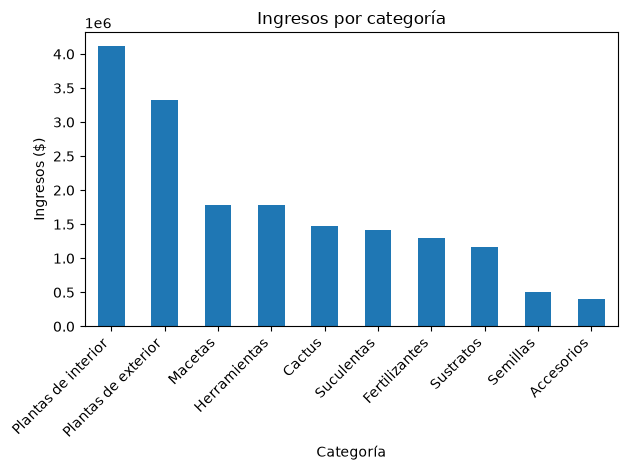

In [ ]:
import matplotlib.pyplot as plt

ingresos_categoria.plot(kind="bar") # genera un gráfico de barras 

plt.title("Ingresos por categoría") # agrega un título al gráfico
plt.xlabel("Categoría") # nombra el eje x
plt.ylabel("Ingresos ($)") # nombra el eje y
plt.xticks(rotation=45, ha="right") # inclina los nombres del eje x para que no se superpongan
plt.tight_layout() # ajusta el diseño del gráfico para que no se corten los elementos
plt.show() # muestra el gráfico

In [41]:
ventas_productos_categorias["ganancia"] = (
    ventas_productos_categorias["precio_venta"] - ventas_productos_categorias["costo"]
) * ventas_productos_categorias["cantidad"]

ventas_productos_categorias.head()

,id_detalle,id_producto,id_venta,precio_venta,cantidad,ingresos,producto,id_categoria,costo,ubicacion,precio_actual,categoria,ganancia
0,1,10,1,4500.0,1,4500.0,Romero,2,1800.0,Sector B,4500.0,Plantas de exterior,2700.0
1,2,18,1,4300.0,2,8600.0,Haworthia,3,1700.0,Sector C,4300.0,Suculentas,5200.0
2,3,28,2,6500.0,3,19500.0,Maceta cerámica 15 cm,5,3000.0,Sector E,6500.0,Macetas,10500.0
3,4,29,3,8075.0,2,16150.0,Maceta cerámica 20 cm,5,4200.0,Sector E,8500.0,Macetas,7750.0
4,5,35,4,3780.0,1,3780.0,Hormona enraizante,6,1800.0,Sector F,4200.0,Fertilizantes,1980.0


In [44]:
ganancia_categoria = (
    ventas_productos_categorias
    .groupby("categoria")["ganancia"]
    .sum()
    .sort_values(ascending=False)
)

ganancia_categoria

categoria
Plantas de interior    2121835.0
Plantas de exterior    1821360.0
Herramientas            969030.0
Macetas                 930535.0
Cactus                  848605.0
Suculentas              823985.0
Fertilizantes           699195.0
Sustratos               650430.0
Semillas                298870.0
Accesorios              238630.0
Name: ganancia, dtype: float64

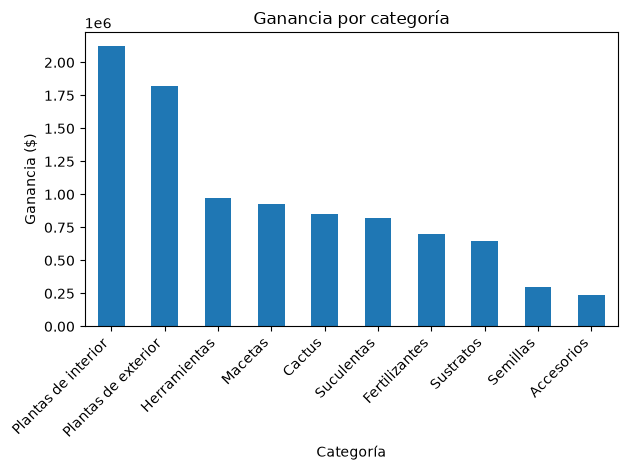

In [45]:
import matplotlib.pyplot as plt

ganancia_categoria.plot(kind="bar") 

plt.title("Ganancia por categoría") 
plt.xlabel("Categoría")
plt.ylabel("Ganancia ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()